# Sentinela: registros de alto risco, totens e previsão em Rondônia

De 2019 a 2024, o sistema de ocorrências da segurança pública de Rondônia acumulou mais de um milhão de registros. Parte deles é classificada pela própria fonte como de alto risco. Este notebook percorre três perguntas sobre esses registros e mostra o que eles permitem, e o que não permitem, afirmar:

1. **Onde** se concentram os registros de alto risco?
2. **Quão perto** eles estão dos totens de segurança cadastrados?
3. **Dá para prever** quantos registros virão nos próximos 30 dias?

### Em resumo, nos dados reais

- Depois da reconciliação, as 1.248.082 linhas viram **1.215.776 protocolos**; **100.607** são de alto risco.
- Os registros de alto risco são **dispersos**: o DBSCAN (150 m, mínimo de 50) encontra 4 clusters e cerca de 98% de ruído, e nenhuma célula agrupada se repete entre os dois semestres.
- Para prever o volume diário, a **média por dia da semana venceu** o boosting no teste: MAE de 8,39 contra 8,69 registros por dia.

> **Os números calculados abaixo são sintéticos.** Dados, geografia e equipamentos são gerados com semente fixa (42) para demonstrar o método sem expor o acervo real, que é privado. Cada seção traz, em destaque, o resultado real correspondente, que também está no [README](../README.md) e na [narrativa do case](../docs/17_portfolio_case.md).

O projeto nasceu como TCC em grupo na FGV, em 2024, e foi reconstruído depois como este case; a [origem acadêmica](../docs/20_origem_tcc.md) conta o que mudou. A [metodologia completa](../docs/15_case_data_science.md) detalha critérios, modelos e testes. Minha contribuição foi a engenharia e o analytics: preparação segura dos dados, qualidade, referências, análise espacial, previsão e comunicação.

In [1]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
from totens.portfolio.case import run_case, load_case

# Para ler uma execução privada existente, informe seu diretório explicitamente
# por TOTENS_PORTFOLIO_RUN. Não existe seleção automática da base real.
existing_run = os.getenv('TOTENS_PORTFOLIO_RUN')
RUN_DIR = Path(existing_run).resolve() if existing_run else run_case(mode='synthetic', project=PROJECT_ROOT)
result = load_case(RUN_DIR, project=PROJECT_ROOT)
SINTETICO = result['mode'] == 'synthetic'


def num(valor, casas=0):
    """Número no formato brasileiro, como 1.234,5."""
    texto = f"{valor:,.{casas}f}"
    return texto.replace(',', '_').replace('.', ',').replace('_', '.')


def pct(fracao, casas=1):
    return f"{num(100 * fracao, casas)}%"


MODELOS = {'seasonal_week': 'Repetição da última semana', 'weekday_84': 'Média por dia da semana (84 dias)'}


def modelo(nome):
    if nome in MODELOS:
        return MODELOS[nome]
    taxa, folhas = nome.removeprefix('poisson_lr').split('_leaf')
    return f"Boosting Poisson (taxa {num(int(taxa) / 100, 2)}; {folhas} folhas)"


display(Markdown(f"**Modo: {result['mode']} — execução: {result['run_id']}**"))

**Modo: synthetic — execução: portfolio_final_20261007**

## 1. Do acervo à unidade de análise

Antes de contar qualquer coisa, é preciso decidir **o que conta como um registro**. O mesmo protocolo aparece em mais de uma extração: a maioria das repetições é idêntica, mas algumas divergem. Em vez de supor que o arquivo mais recente está certo, cada protocolo é reconciliado. Data e risco precisam concordar entre as versões; o que conflita sai da análise principal, com contagem explícita.

O alvo é a classificação de risco da própria fonte, nível alto ou superior, e a data é a de criação do registro, no fuso de Porto Velho. Classificação desconhecida continua desconhecida, sem ser forçada para outra categoria.

> **Nos dados reais:** 1.248.082 linhas e 1.215.776 protocolos distintos. Das 32.306 repetições excedentes, 31.956 são idênticas e 350 têm diferenças. São 100.607 protocolos de alto risco.

- Linhas recebidas: **42.454**
- Protocolos distintos: **40.848**
- Repetições excedentes: **1.606**, sendo 1.309 idênticas e 297 com diferenças

,Protocolos
Alto risco,22.890
Demais níveis,17.786
Risco desconhecido,101
Risco conflitante,40
Data inválida ou conflitante,31


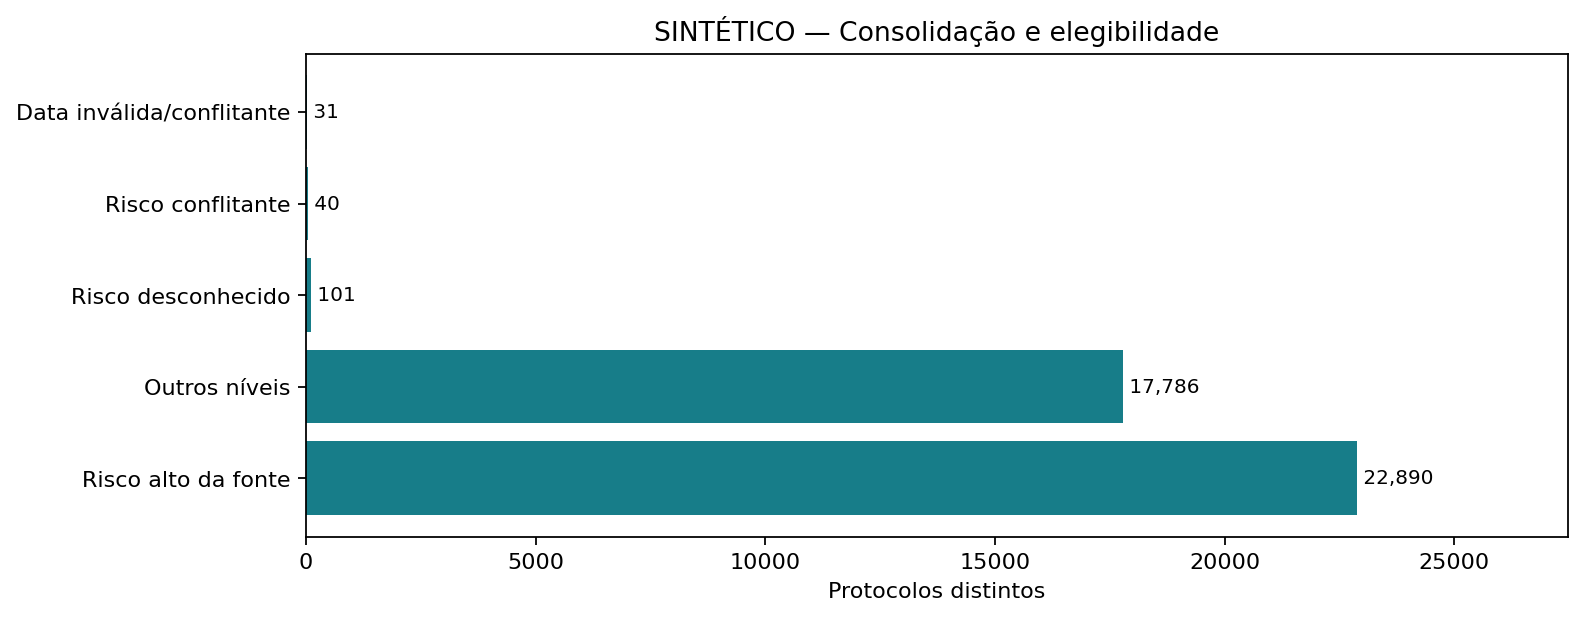

Na demonstração nenhuma base real é lida; a conciliação com o pipeline anterior e as referências reais não se aplicam.

In [2]:
quality = result['quality']
display(Markdown(
    f"- Linhas recebidas: **{num(quality['input_rows'])}**\n"
    f"- Protocolos distintos: **{num(quality['distinct_protocols'])}**\n"
    f"- Repetições excedentes: **{num(quality['excess_rows'])}**, sendo {num(quality['identical_excess_rows'])} idênticas "
    f"e {num(quality['different_excess_rows'])} com diferenças"))
ROTULOS = {'known_high': 'Alto risco', 'known_other': 'Demais níveis', 'risk_unknown': 'Risco desconhecido',
           'risk_conflicting': 'Risco conflitante', 'date_invalid_or_conflicting': 'Data inválida ou conflitante'}
display(pd.Series(quality['partition']).rename(index=ROTULOS).map(num).to_frame('Protocolos'))
display(Image(filename=str(RUN_DIR / 'figures/quality.png')))
if SINTETICO:
    display(Markdown('Na demonstração nenhuma base real é lida; a conciliação com o pipeline anterior e as referências reais não se aplicam.'))
else:
    display(Markdown(str(result['legacy_reconciliation'])))
    display(pd.Series(result.get('references') or {}, name='Referências').to_frame())

## 2. O tempo

Uma série diária parece simples, mas três cuidados mudam a leitura:

- **Zero não é lacuna.** Um dia sem registros no acervo é um zero observado; um período sem extração é ausente e fica fora da série.
- **Meses incompletos ficam de fora** da modelagem, e só meses completos e vizinhos entram na comparação de variações mensais.
- **Picos são sinalizados, não apagados.** Antes de atribuí-los a mudanças na criminalidade, é preciso investigar a cobertura da extração, a origem e as atualizações dos registros.

A tabela final mostra a média diária por dia da semana, o padrão que os modelos de previsão precisam capturar. O padrão por hora não aparece porque, na demonstração, todos os registros sintéticos têm o mesmo horário.

> **Nos dados reais:** a série modelada vai de março de 2019 a outubro de 2024, com 2.072 dias.

Período observado: **2021-01-01** a **2024-06-30**, 1.277 dias, com 0 dias de lacuna.

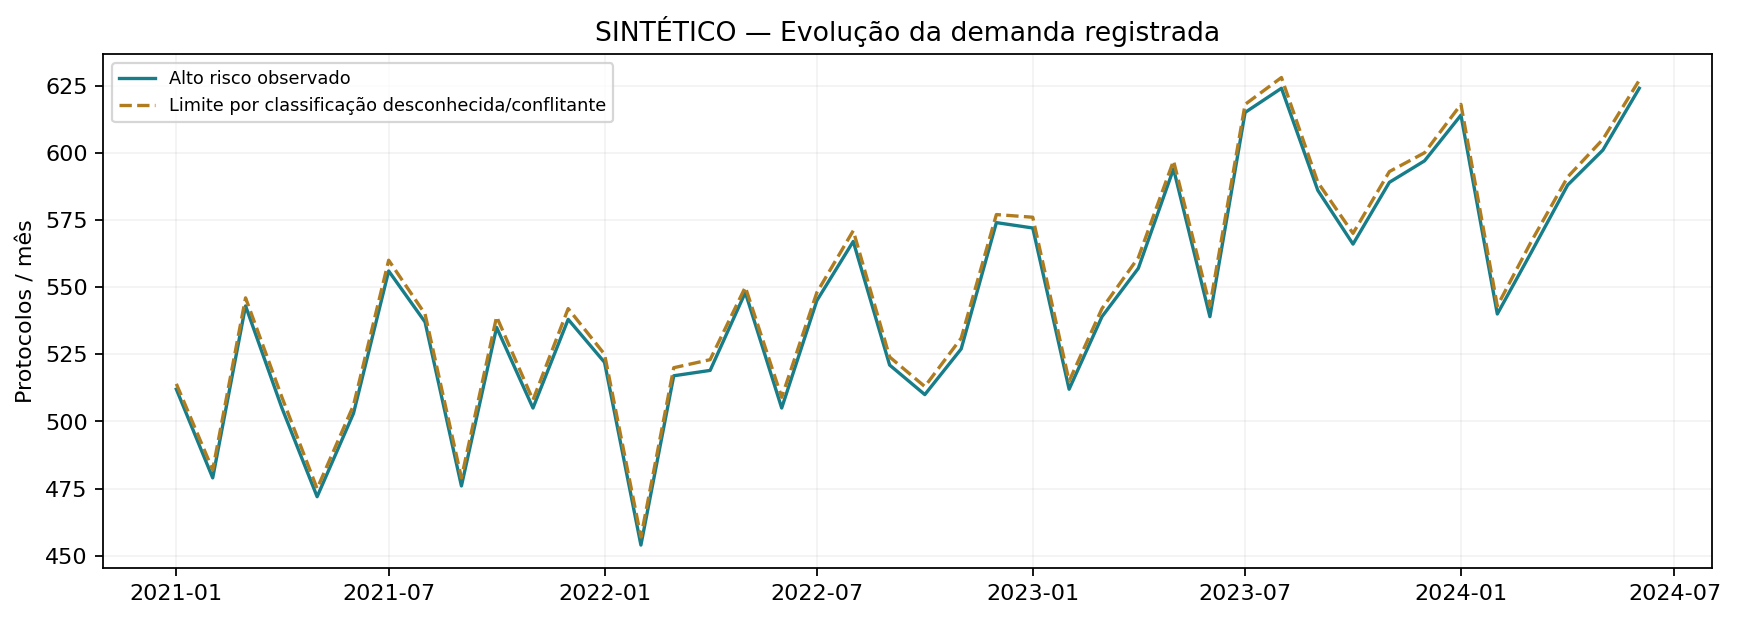

Nenhuma variação acima do dobro ou abaixo da metade entre meses completos vizinhos.

,Média diária de alto risco
Segunda,"19,2"
Terça,"19,4"
Quarta,"19,3"
Quinta,"20,4"
Sexta,"19,6"
Sábado,"14,0"
Domingo,"13,7"


In [3]:
temporal = result['temporal']
daily = pd.read_csv(RUN_DIR / 'daily.csv', parse_dates=['date'])
display(Markdown(f"Período observado: **{temporal['start_date']}** a **{temporal['end_date']}**, "
                 f"{num(temporal['calendar_days'])} dias, com {num(temporal['gap_days'])} dias de lacuna."))
display(Image(filename=str(RUN_DIR / 'figures/monthly.png')))
if temporal.get('large_monthly_changes'):
    display(pd.Series(temporal['large_monthly_changes'], name='Razão entre meses completos').to_frame())
else:
    display(Markdown('Nenhuma variação acima do dobro ou abaixo da metade entre meses completos vizinhos.'))
DIAS = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']
completos = daily[daily['complete_month'] & daily['y'].notna()]
por_dia = completos.groupby(completos['date'].dt.dayofweek)['y'].mean()
display(pd.DataFrame({'Média diária de alto risco': [num(v, 1) for v in por_dia]}, index=[DIAS[d] for d in por_dia.index]))

## 3. Onde e quão perto

**Proximidade** é medida de forma geométrica: a distância de cada registro ao totem mais próximo do cadastro, nos raios de 150, 300 e 500 metros. Isso descreve cobertura, não efeito, porque o cadastro não traz as datas de operação de cada equipamento.

**Concentração** é investigada de duas formas. Uma grade de células de 1 km dá a visão descritiva. O DBSCAN procura agrupamentos densos com uma configuração fixada antes dos resultados (150 metros e mínimo de 50 registros), e nove combinações de parâmetros testam a sensibilidade.

A pergunta decisiva é se os agrupamentos **persistem**. A última tabela compara os dois semestres da janela de 12 meses pela sobreposição das células ocupadas.

> **Nos dados reais:** na janela de novembro de 2023 a outubro de 2024, os 16.073 registros de alto risco formam 4 clusters, com cerca de 98% de ruído, e a sobreposição entre semestres é zero (Jaccard 0).
>
> **Por que a demonstração difere:** o gerador sintético concentra registros perto de poucos pontos fictícios. Por isso a demo mostra pouco ruído e clusters estáveis, o oposto do acervo real. O polígono do estado também é uma área fictícia.

- Protocolos de alto risco: **22.890**; com localização válida no estado: **22.832** (58 com coordenada inválida ou conflitante e 0 fora de RO)
- Janela de 12 meses: 2023-07-01 a 2024-06-30, com **7.087** registros

,Todo o período,Janela de 12 meses
Até 150 m de um totem,"60,9%","61,7%"
Até 300 m de um totem,"61,6%","62,4%"
Até 500 m de um totem,"61,7%","62,4%"


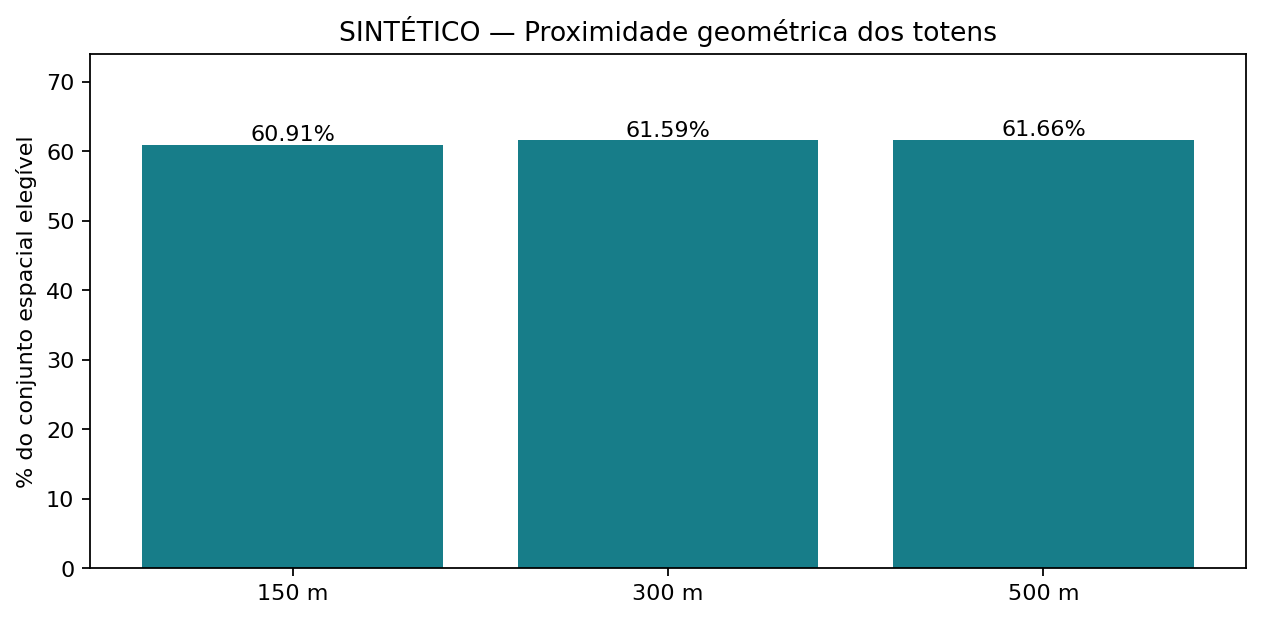

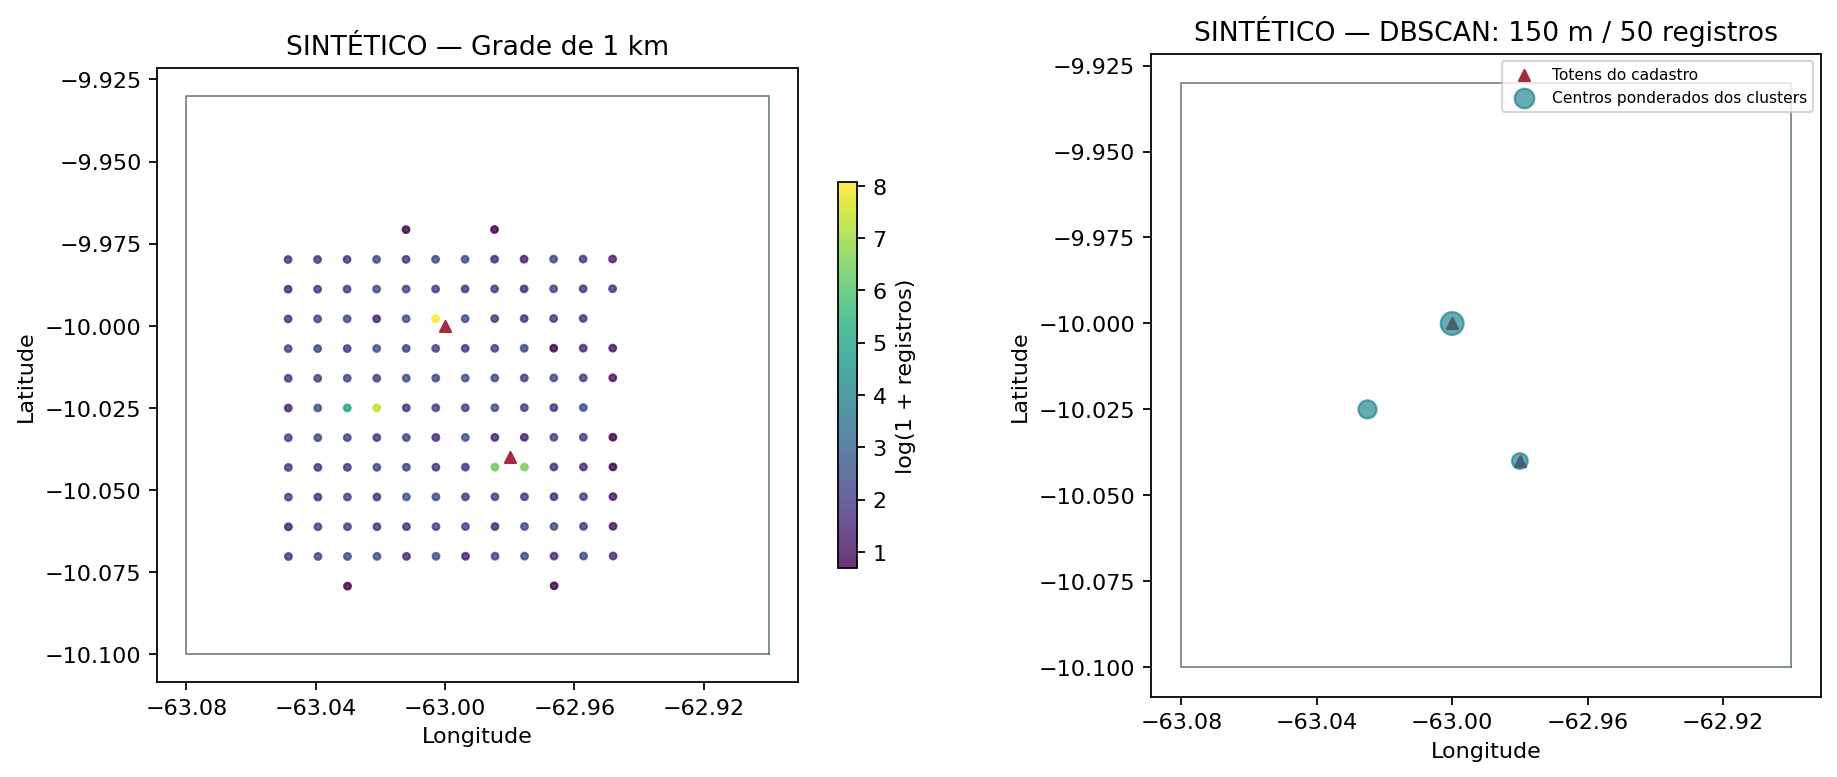

Clusters  Ruído Maior cluster
Raio (m) Mínimo de registros                               
100      25                          3  12,1%         3.190
         50                          3  12,1%         3.190
         100                         3  12,1%         3.190
150      25                          3  12,0%         3.190
         50                          3  12,0%         3.190
         100                         3  12,1%         3.190
300      25                          3  11,9%         3.193
         50                          3  11,9%         3.193
         100                         3  11,9%         3.193

,Clusters,Ruído,Maior cluster
1º semestre,3,"12,2%",1.610
2º semestre,3,"11,9%",1.580


Sobreposição das células agrupadas entre os semestres: **Jaccard = 0,86**. Volumes semestrais diferentes e o mínimo fixo de registros também afetam essa medida.

In [4]:
spatial = result['spatial']
display(Markdown(
    f"- Protocolos de alto risco: **{num(spatial['high_risk_protocols'])}**; com localização válida no estado: "
    f"**{num(spatial['spatial_eligible'])}** ({num(spatial['high_risk_coordinate_invalid_or_conflicting'])} com coordenada "
    f"inválida ou conflitante e {num(spatial['high_risk_outside_ro'])} fora de RO)\n"
    f"- Janela de 12 meses: {spatial['window_start']} a {spatial['window_end']}, com **{num(spatial['window_records'])}** registros"))
cobertura = pd.DataFrame({
    'Todo o período': {r: pct(v['fraction']) for r, v in spatial['coverage'].items()},
    'Janela de 12 meses': {r: pct(v['fraction']) for r, v in spatial['window_coverage'].items()},
})
cobertura.index = [f'Até {r} m de um totem' for r in cobertura.index]
display(cobertura)
display(Image(filename=str(RUN_DIR / 'figures/coverage.png')))
display(Image(filename=str(RUN_DIR / 'figures/spatial.png')))
sens = pd.read_csv(RUN_DIR / 'cluster_sensitivity.csv')
display(pd.DataFrame({'Raio (m)': sens['eps_m'], 'Mínimo de registros': sens['min_samples'], 'Clusters': sens['clusters'],
                      'Ruído': sens['noise_fraction'].map(pct),
                      'Maior cluster': sens['largest_cluster_records'].map(num)}).set_index(['Raio (m)', 'Mínimo de registros']))
semestres = pd.read_csv(RUN_DIR / 'semester_comparison.csv')
display(pd.DataFrame({'Clusters': semestres['clusters'].values, 'Ruído': semestres['noise_fraction'].map(pct).values,
                      'Maior cluster': semestres['largest_cluster_records'].map(num).values},
                     index=semestres['period'].map({'first_semester': '1º semestre', 'second_semester': '2º semestre'}).values))
jaccard = spatial['semester_clustered_grid_jaccard']
display(Markdown(f"Sobreposição das células agrupadas entre os semestres: **Jaccard = {'indefinido' if jaccard is None else num(jaccard, 2)}**. "
                 "Volumes semestrais diferentes e o mínimo fixo de registros também afetam essa medida."))

## 4. Dá para prever?

O alvo é a contagem diária de registros de alto risco, 30 dias à frente. Para valer a pena, um modelo precisa vencer referências simples:

- **repetir a última semana**;
- **média por dia da semana** dos últimos 84 dias;
- **boosting Poisson** (HistGradientBoosting), em quatro configurações fixadas de antemão.

Os atributos usam só o passado: defasagens de 1, 7, 14 e 28 dias, médias móveis deslocadas e calendário. O horizonte é recursivo; dentro dos 30 dias, previsões anteriores ocupam o lugar dos valores futuros desconhecidos.

A avaliação imita o uso real. Seis blocos de validação, com treino crescente, escolhem o modelo, que fica **congelado** antes dos três blocos finais de teste (90 dias); o resultado do teste não reabre a escolha. MAE e RMSE estão em registros por dia, e o MASE compara o erro com a variação semanal do treino. Na tabela, a estrela marca o modelo escolhido.

> **Nos dados reais:** a validação escolheu o boosting Poisson (taxa 0,05; 15 folhas). No teste, ele teve MAE de 8,69 registros por dia, contra 8,39 da média por dia da semana. Um experimento separado com feriados nacionais e estaduais reduziu o MAE de validação em cerca de 1,55%, sem reavaliar o teste.
>
> **Por que a demonstração difere:** na série sintética, a média por dia da semana já é escolhida na validação e o resultado empata no teste.

Série: 2021-01-01 a 2024-06-30; teste final: 2024-04-02 a 2024-06-30.

Escolhido na validação: **Média por dia da semana (84 dias)**, com MAE de teste de **4,50** registros/dia; o melhor baseline teve **4,50**.

MAE  RMSE  MASE
Etapa     Modelo                                                   
Validação Boosting Poisson (taxa 0,05; 15 folhas)  3,74  4,83  0,81
          Boosting Poisson (taxa 0,05; 31 folhas)  3,83  4,94  0,83
          Boosting Poisson (taxa 0,10; 15 folhas)  3,80  4,89  0,82
          Boosting Poisson (taxa 0,10; 31 folhas)  4,02  5,17  0,87
          Média por dia da semana (84 dias) ★      3,55  4,43  0,77
          Repetição da última semana               4,71  5,94  1,02
Teste     Boosting Poisson (taxa 0,05; 15 folhas)  4,40  5,66  0,94
          Boosting Poisson (taxa 0,05; 31 folhas)  4,50  5,86  0,97
          Boosting Poisson (taxa 0,10; 15 folhas)  4,46  5,80  0,96
          Boosting Poisson (taxa 0,10; 31 folhas)  4,37  5,81  0,94
          Média por dia da semana (84 dias) ★      4,50  5,55  0,97
          Repetição da última semana               5,58  6,70  1,20

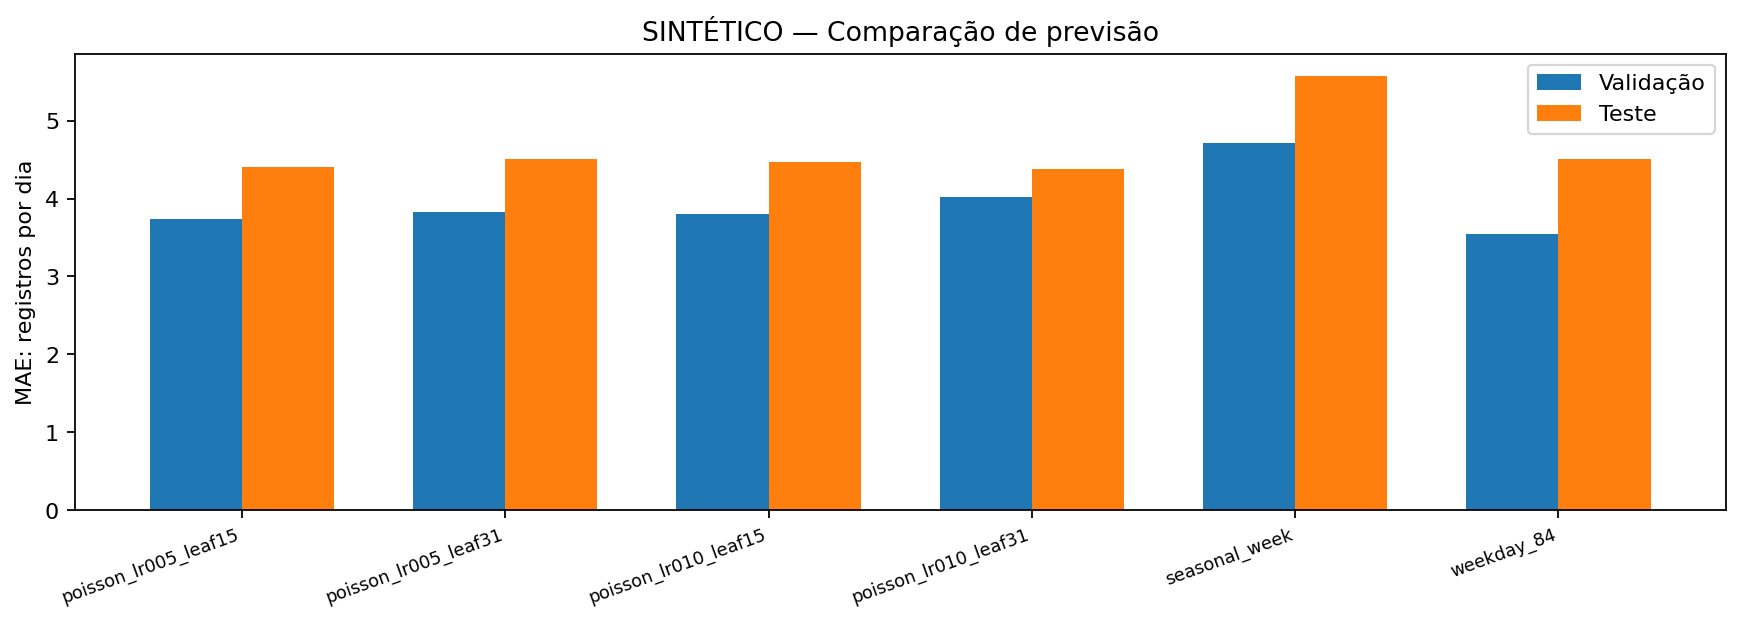

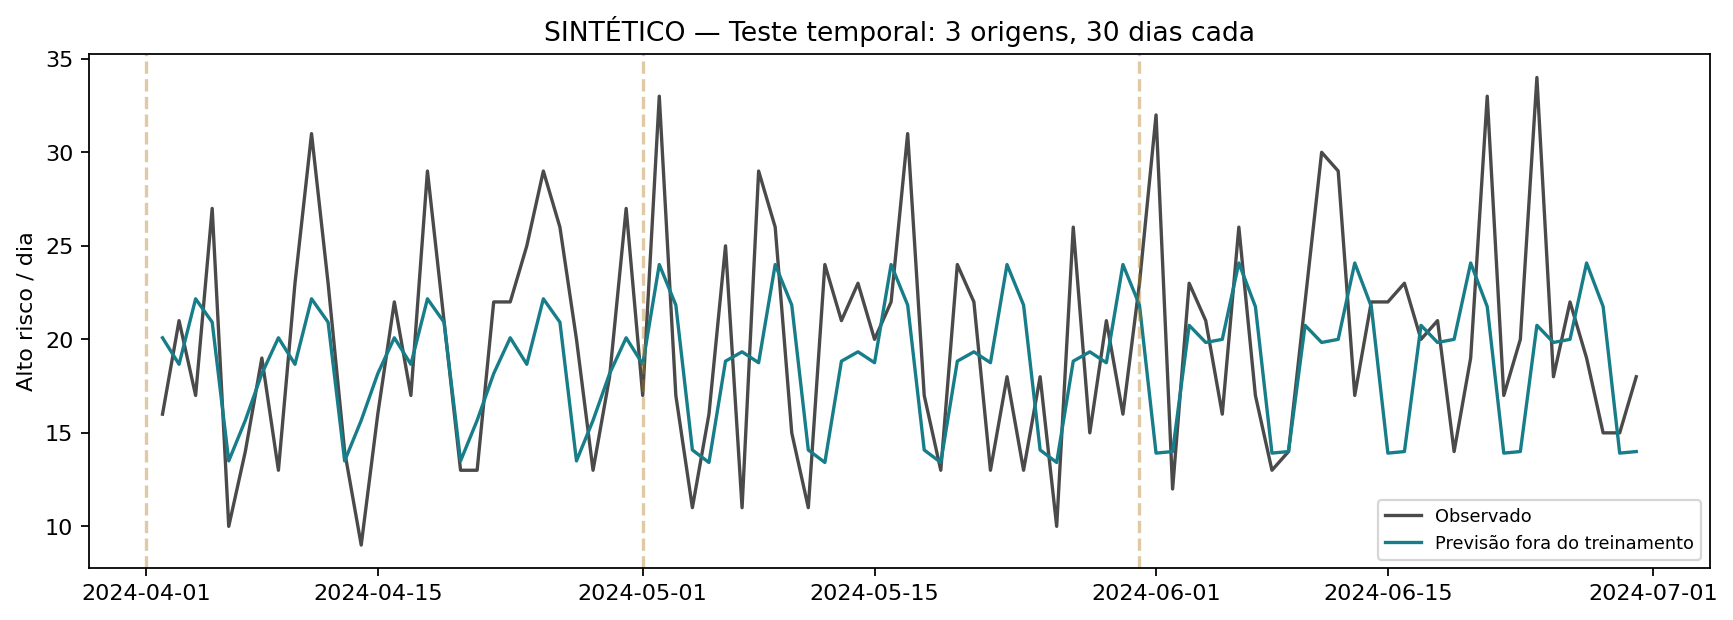

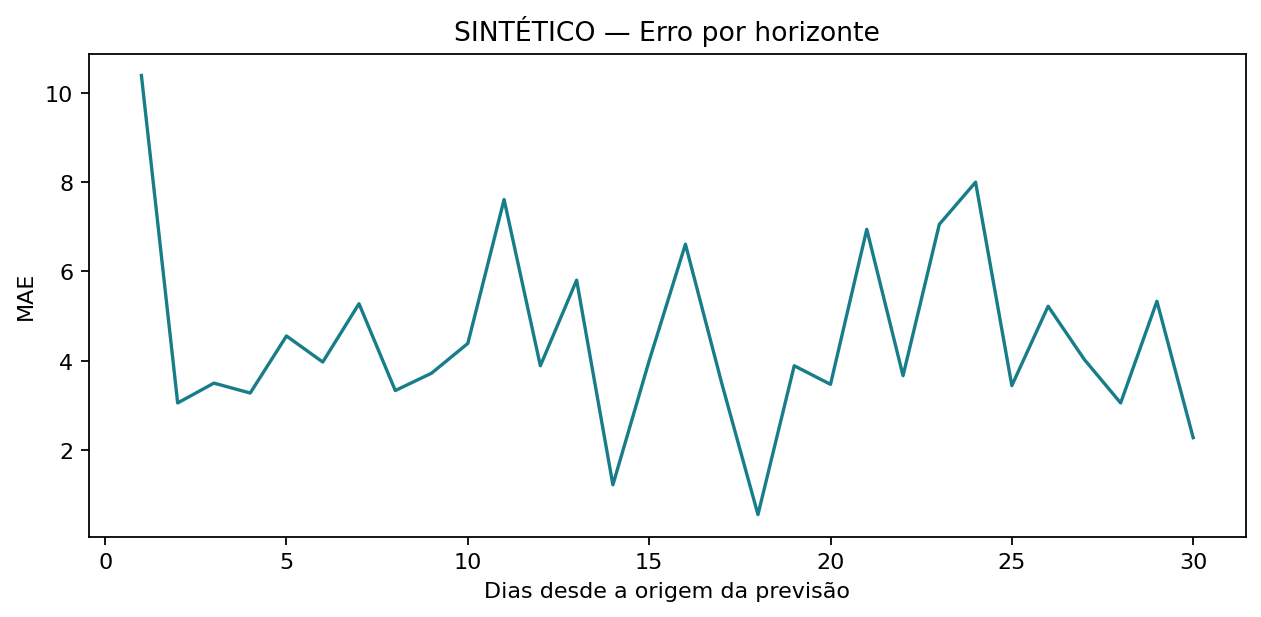

In [5]:
forecast = result['forecast']
display(Markdown(
    f"Série: {forecast['series_start']} a {forecast['series_end']}; teste final: {forecast['test_start']} a {forecast['test_end']}.\n\n"
    f"Escolhido na validação: **{modelo(forecast['selected_model'])}**, com MAE de teste de "
    f"**{num(forecast['selected_test_mae'], 2)}** registros/dia; o melhor baseline teve **{num(forecast['best_baseline_test_mae'], 2)}**."))
desempenho = pd.read_csv(RUN_DIR / 'forecast_performance.csv')
tabela = pd.DataFrame({'Etapa': desempenho['split'].map({'validation': 'Validação', 'test': 'Teste'}),
                       'Modelo': desempenho['model'].map(modelo),
                       'MAE': desempenho['mae'].map(lambda v: num(v, 2)),
                       'RMSE': desempenho['rmse'].map(lambda v: num(v, 2)),
                       'MASE': desempenho['mase'].map(lambda v: '—' if pd.isna(v) else num(v, 2))})
tabela.loc[desempenho['model'].eq(forecast['selected_model']), 'Modelo'] += ' ★'
display(tabela.set_index(['Etapa', 'Modelo']).sort_index(ascending=[False, True]))
display(Image(filename=str(RUN_DIR / 'figures/forecast_comparison.png')))
display(Image(filename=str(RUN_DIR / 'figures/forecast_test.png')))
display(Image(filename=str(RUN_DIR / 'figures/forecast_horizon.png')))

## 5. O que fica

- **Um baseline vencedor é um resultado.** Nos dados reais, a média por dia da semana errou menos que o boosting selecionado no teste. A complexidade não se justificou.
- **Proximidade não é efeito.** Os dados não permitem estimar crimes evitados nem afirmar que os totens funcionaram; os registros são protocolos classificados, não crimes confirmados.
- **Concentração não é permanência.** Os agrupamentos reais mudam entre semestres e servem para investigar, não para decidir onde instalar. Para essa decisão há uma [proposta de cobertura máxima](../docs/19_proposta_cobertura_mclp.md), ainda não executada.
- **Retrospectivo, não operacional.** A disponibilidade das classificações no momento de cada previsão não foi comprovada, e a projeção final é um exercício histórico, sem intervalos probabilísticos.

Cada execução gera um manifesto com versões, estado do Git, hashes dos insumos, parâmetros e artefatos. Os testes alteram o futuro de propósito para verificar que nada vaza para o passado. Os resultados reais detalhados e os mapas ficam privados.

Referências: [DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html) e [features defasadas com avaliação temporal](https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html).

In [6]:
conclusao = ('O modelo escolhido errou mais que o melhor baseline no teste; não há ganho consistente demonstrado.'
             if forecast['selected_test_mae'] > forecast['best_baseline_test_mae']
             else 'O modelo escolhido ficou no mesmo nível ou abaixo do melhor baseline no teste.')
relatorio = ('[relatório da demonstração publicada](../docs/assets/synthetic_demo/report.md)' if SINTETICO
             else '`report.md` no diretório privado desta execução')
display(Markdown(f"""
### Síntese desta execução

- Protocolos de alto risco após consolidação e exclusões: **{num(quality['high_risk_protocols'])}**.
- Até 300 m de um totem: **{pct(spatial['coverage']['300']['fraction'])}** dos {num(spatial['spatial_eligible'])} protocolos com localização válida.
- Escolhido na validação: **{modelo(forecast['selected_model'])}**, com MAE de teste de **{num(forecast['selected_test_mae'], 2)}** registros/dia, contra {num(forecast['best_baseline_test_mae'], 2)} do melhor baseline.

{conclusao}

O teste final mede o desempenho fora do treinamento e não muda a escolha do modelo. Os detalhes estão no {relatorio}.
"""))


### Síntese desta execução

- Protocolos de alto risco após consolidação e exclusões: **22.890**.
- Até 300 m de um totem: **61,6%** dos 22.832 protocolos com localização válida.
- Escolhido na validação: **Média por dia da semana (84 dias)**, com MAE de teste de **4,50** registros/dia, contra 4,50 do melhor baseline.

O modelo escolhido ficou no mesmo nível ou abaixo do melhor baseline no teste.

O teste final mede o desempenho fora do treinamento e não muda a escolha do modelo. Os detalhes estão no [relatório da demonstração publicada](../docs/assets/synthetic_demo/report.md).
